In [1]:
import pandas as pd
import os
import random
import time
from sklearn.model_selection import train_test_split
import torch
import torchvision
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from torchvision.transforms import InterpolationMode
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from tqdm import tqdm
from torchvision import models
import torchvision.transforms.functional as TF
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:
torch.manual_seed(42)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
train_path = '/home/dbtproject/barsha/Image/training_set' 
test_path = '/home/dbtproject/barsha/Image/test_set'

In [5]:
# Show the paths and their types (use type() on a Python object)
print('type(train_path):', type(train_path))

type(train_path): <class 'str'>


In [6]:
print('The training set consists of ', len(os.listdir(train_path +'/Class0_Graminicola')),
 ' Class0_Graminicola images,', len(os.listdir(train_path + '/Class1_Incognita')), 
 'Class1_Incognita images and ', len(os.listdir(train_path + '/Class2_Javanica')), ' Class2_Javanica images.' )

The training set consists of  139  Class0_Graminicola images, 55 Class1_Incognita images and  83  Class2_Javanica images.


In [7]:
print('The test set consists of ', len(os.listdir(test_path +'/Class0_Graminicola')), 
 ' Class0_Graminicola images,', len(os.listdir(test_path +'/Class1_Incognita')), 
 'Class1_Incognita images and ', len(os.listdir(test_path +'/Class2_Javanica')), ' Class2_Javanica images.' )

The test set consists of  35  Class0_Graminicola images, 14 Class1_Incognita images and  21  Class2_Javanica images.


In [8]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


In [9]:
import os
import pandas as pd
from PIL import Image

def images_to_dataframe(root_dir):
    rows = []

    # root_dir should contain subfolders (classes)
    for label in os.listdir(root_dir):
        class_path = os.path.join(root_dir, label)
        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            file_path = os.path.join(class_path, filename)

            # Open the image to get size
            try:
                with Image.open(file_path) as img:
                    width, height = img.size
            except:
                continue
            
            rows.append({
                "filename": filename,
                "path": file_path,
                "label": label,
            
            })

    return pd.DataFrame(rows)


# Example: train and test DataFrames
train_df = images_to_dataframe("/home/dbtproject/barsha/Image/training_set")
test_df = images_to_dataframe("/home/dbtproject/barsha/Image/test_set")

print(train_df.head())
print(train_df.shape)
print(test_df.shape)


              filename                                               path  \
0       S-57_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
1       D-30_PP_5.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
2  D-38_PP_Good_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
3       ES-3_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   
4       G-60_PP_4.tiff  /home/dbtproject/barsha/Image/training_set/Cla...   

                label  
0  Class0_Graminicola  
1  Class0_Graminicola  
2  Class0_Graminicola  
3  Class0_Graminicola  
4  Class0_Graminicola  
(277, 3)
(70, 3)


In [10]:
train_df.head()

,filename,path,label
0,S-57_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
1,D-30_PP_5.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
2,D-38_PP_Good_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
3,ES-3_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola
4,G-60_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,Class0_Graminicola


In [11]:
train_df['label'].value_counts()


label
Class0_Graminicola    139
Class2_Javanica        83
Class1_Incognita       55
Name: count, dtype: int64

In [12]:
RANDOM_STATE = 42
VAL_SIZE = 0.20   # 20% validation

train_df, val_df = train_test_split(
    train_df,
    test_size=VAL_SIZE,
    stratify=train_df['label'],
    random_state=RANDOM_STATE
)

print("After split:")
print("Train split counts:\n", train_df['label'].value_counts().sort_index())
print("Val split counts:\n", val_df['label'].value_counts().sort_index())



After split:
Train split counts:
 label
Class0_Graminicola    111
Class1_Incognita       44
Class2_Javanica        66
Name: count, dtype: int64
Val split counts:
 label
Class0_Graminicola    28
Class1_Incognita      11
Class2_Javanica       17
Name: count, dtype: int64


In [13]:
train_df.shape

(221, 3)

In [14]:
test_df.shape

(70, 3)

In [15]:
val_df.shape

(56, 3)

In [16]:
le = LabelEncoder()
# Fit on training labels and transform train/val/test appropriately
train_df['label'] = le.fit_transform(train_df['label'])
val_df['label'] = le.transform(val_df['label'])
test_df['label'] = le.transform(test_df['label'])
train_df.head(150)

 

,filename,path,label
98,D-35_PP_2.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
34,D-95_PP_2.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
122,D-85_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
152,Meloidogyne javanica_42.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,2
58,D-38_PP_6.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
...,...,...,...
171,Meloidogyne javanica_9.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,2
4,G-60_PP_4.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
81,J-1_PP_3.tiff,/home/dbtproject/barsha/Image/training_set/Cla...,0
256,Meloidogyne incognita_56.jpeg,/home/dbtproject/barsha/Image/training_set/Cla...,1


In [17]:
import pandas as pd

mapping_df = pd.DataFrame({
    "Original_Label": le.classes_,
    "Encoded_Label": le.transform(le.classes_)
})

print(mapping_df)


       Original_Label  Encoded_Label
0  Class0_Graminicola              0
1    Class1_Incognita              1
2     Class2_Javanica              2


In [18]:
train_df['label'].unique()

array([0, 2, 1])

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize(232, interpolation=InterpolationMode.BILINEAR),  # Resize images to a common size
    transforms.CenterCrop(224),
    transforms.RandomHorizontalFlip(),  # Data augmentation
    transforms.RandomVerticalFlip(),  # Data augmentation
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normalize with ImageNet stats
])

val_test_transform = transforms.Compose([
    transforms.Resize((232)),
    transforms.CenterCrop((224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [20]:
from torch.utils.data import Dataset
from PIL import Image

class DeterministicRotationDataset(Dataset):
    def __init__(self, df, img_col, label_col, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_col = img_col
        self.label_col = label_col
        self.transform = transform

        self.angles = list(range(0, 360, 10))   # 72 rotations

    def __len__(self):
        return len(self.df) * len(self.angles)

    def __getitem__(self, idx):

        img_idx = idx // len(self.angles)
        angle_idx = idx % len(self.angles)

        row = self.df.iloc[img_idx]

        img = Image.open(row[self.img_col]).convert("RGB")
        label = int(row[self.label_col])

        angle = self.angles[angle_idx]
        img = TF.rotate(img, angle)

        if self.transform:
            img = self.transform(img)

        return img, label

In [21]:
class DFImageDataset(Dataset):
    def __init__(self, df, img_col='path', label_col='label', transform=None):
        
        self.df = df.reset_index(drop=True)
        self.img_col = img_col
        self.label_col = label_col
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row[self.img_col]
        # load image (PIL)
        img = Image.open(img_path).convert('RGB')
        
        if self.transform:
            img = self.transform(img)
        else:
            # default
            img = transforms.ToTensor()(img)
        label = int(row[self.label_col])
        return img, label


In [22]:
train_data = DeterministicRotationDataset(train_df, img_col='path', label_col='label', transform=train_transform)
val_data   = DFImageDataset(val_df,   img_col='path', label_col='label', transform=val_test_transform)
test_data  = DFImageDataset(test_df,  img_col='path', label_col='label', transform=val_test_transform)



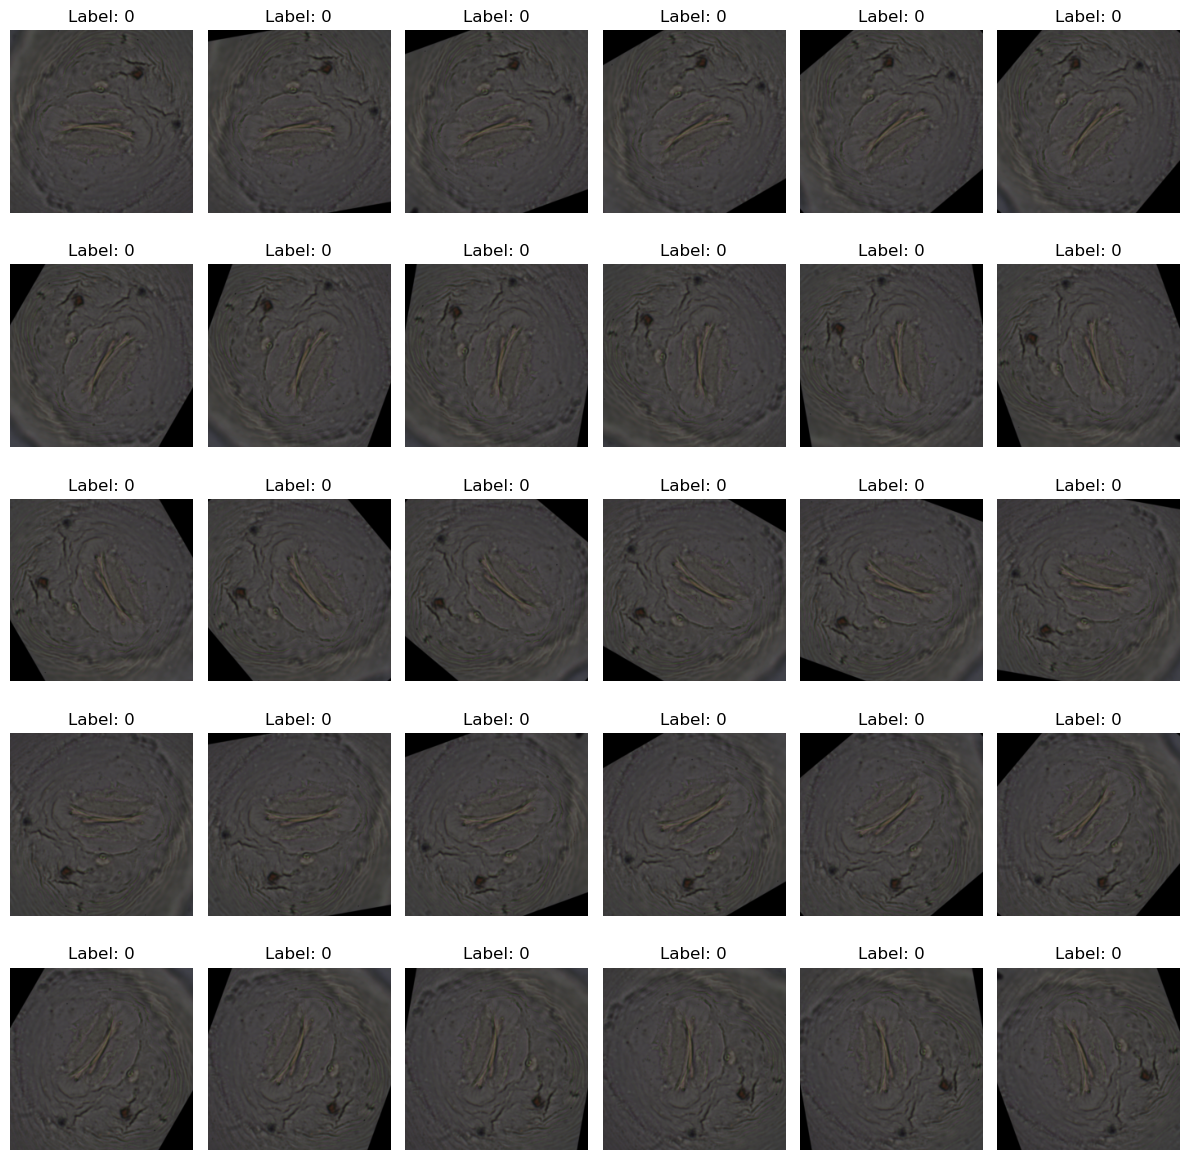

In [23]:
n_rows =5
n_cols =6
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 12))
axes = axes.flatten()
for row in range(n_rows):
    for col in range(n_cols):
        idx = row * n_cols + col
        img, label = train_data[idx]
        img = img.permute(1, 2, 0).numpy()  # Convert from (C, H, W) to (H, W, C)
        img = np.clip(img * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406]), 0, 1)  # Denormalize
        axes[idx].imshow(img)
        axes[idx].set_title(f'Label: {label}')
        axes[idx].axis('off')
plt.tight_layout()
plt.show()

In [24]:
# get labels as numpy array from train_df (the split)
train_labels = train_df['label'].values
classes, class_counts = np.unique(train_labels, return_counts=True)
print("Classes:", classes)
print("Class counts:", class_counts)

# weight per class: inverse of count
class_weights = {cls: 1.0 / count for cls, count in zip(classes, class_counts)}
print("Class weights:", class_weights)

# sample weight for each sample in the training split
sample_weights = train_df['label'].map(class_weights).values  # pandas Series -> numpy

sample_weights = np.repeat(sample_weights, 36) #72 rotation 

# convert to torch tensor
sample_weights_tensor = torch.from_numpy(sample_weights.astype(np.float32))

# create WeightedRandomSampler
num_samples = len(sample_weights_tensor)   # usually equals len(train_dataset)
sampler = WeightedRandomSampler(weights=sample_weights_tensor, num_samples=num_samples, replacement=True)


Classes: [0 1 2]
Class counts: [111  44  66]
Class weights: {np.int64(0): np.float64(0.009009009009009009), np.int64(1): np.float64(0.022727272727272728), np.int64(2): np.float64(0.015151515151515152)}


In [25]:
#configuration
NUM_EPOCHS = 5
LR = 0.001  #1e-4
BATCH_SIZE = 64
LAMBDA_LOGIT = 0.5
LAMBDA_FEAT = 0.2
# Eval_batch_size = 16
weight_decay = 0.01
NUM_WORKERS = 4
PIN_MEMORY = True
# Path to checkpoint file (use a project-local checkpoints directory)
# import os
# CHECKPOINT_DIR = os.path.join('/home/dbtproject/barsha/np_code_new', 'checkpoints')
# os.makedirs(CHECKPOINT_DIR, exist_ok=True)
# CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, 'resnet50_best_model.pth')
# # os.makedirs(os.path.dirname(CHECKPOINT_PATH) or '.', exist_ok=True)


In [26]:

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    sampler=sampler,  # use the weighted sampler
    # num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
#     num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    # num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

In [27]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)


In [28]:
model

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [29]:
print(model.fc.in_features)

2048


In [30]:
#modify final layer

in_features = model.fc.in_features
num_classes = len(le.classes_)  # number of unique labels
model.fc = nn.Linear(in_features, num_classes)

In [31]:
model.fc

Linear(in_features=2048, out_features=3, bias=True)

In [32]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

In [33]:
model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [34]:
model.parameters

<bound method Module.parameters of ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 2

In [35]:
optimizer = optim.Adam(model.parameters(), lr=LR) 
# weight_decay=weight_decay
criterion = nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
best_val_accuracy = 0


In [36]:
# def forward_with_features(model, x):
#     x = model.conv1(x)
#     x = model.bn1(x)
#     x = model.relu(x)
#     x = model.maxpool(x)

#     x = model.layer1(x)
#     x = model.layer2(x)
#     x = model.layer3(x)
#     x = model.layer4(x)

#     x = model.avgpool(x)
#     features = torch.flatten(x, 1)

#     logits = model.fc(features)
#     return logits, features


In [37]:
history = {'train_loss': [],
           'val_loss': [],
           'train_accuracy': [],
           'val_accuracy': [],
           'epoch': []}

In [38]:
# for epoch in range(1, NUM_EPOCHS + 1):
#     epoch_start = time.time()
#     print(f'Epoch {epoch}/{NUM_EPOCHS}')
    
#     # Training phase
#     model.train()
#     tr_acc= 0.0
#     tr_loss = 0.0
#     val_loss = 0.0
#     val_acc = 0.0

#     for inputs, labels in train_loader:
#         inputs, labels = inputs.to(device), labels.to(device)
#         batch_size = inputs.size(0)

#         optimizer.zero_grad()

#         outputs = model(inputs.float())
#         outputs_rs = outputs.view(batch_size, num_classes)
#         loss = criterion(outputs_rs, labels)
#         loss.backward()
#         optimizer.step()

#         tr_loss += loss.item() * batch_size  # accumulate total loss

#     # Validation phase
#     model.eval()

#     with torch.no_grad():
#         for inputs, labels in val_loader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             batch_size = inputs.size(0)

#             outputs = model(inputs.float())
#             outputs_rs = outputs.view(batch_size, num_classes)
#             loss = criterion(outputs_rs, labels)
    #         val_loss += loss.item() * batch_size

    # val_loss = val_loss / len(val_loader.dataset)

In [39]:
!nvidia-smi

Thu Feb 26 12:36:24 2026       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.183.01             Driver Version: 535.183.01   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA RTX A6000               Off | 00000000:01:00.0 Off |                  Off |
| 30%   39C    P2              37W / 300W |    393MiB / 49140MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [40]:
# import torchvision.transforms.functional as TF

# def tta_predict(model, image, device, angles):
#     model.eval()
#     preds = []

#     with torch.no_grad():
#         for angle in angles:
#             img_rot = TF.rotate(image, angle)
#             output = model(img_rot.unsqueeze(0).to(device))
#             prob = torch.softmax(output, dim=1)
#             preds.append(prob)

#     mean_pred = torch.mean(torch.stack(preds), dim=0)
#     return mean_pred


In [41]:
# import copy
# import os
# for epoch in range(1, NUM_EPOCHS+1):
#     epoch_start = time.time()
#     print(f'Epoch {epoch}/{NUM_EPOCHS}')
    
#     # Training phase
#     model.train()
#     running_loss = 0.0
#     running_correct = 0
#     running_total = 0

#     train_bar = tqdm(train_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Training', leave=False)
#     for inputs, labels in train_bar:
#         inputs, labels = inputs.to(device), labels.to(device)
#         batch_size = inputs.size(0)

#         optimizer.zero_grad()

#         angles = torch.randint(0, 360, (batch_size,), device=device).float()

#         rotated_inputs = torch.stack([
#             TF.rotate(img, angle.item())
#             for img, angle in zip(inputs, angles)
#         ])

#         # Forward pass
#         logits1, feat1 = forward_with_features(model, inputs.float())
#         logits2, feat2 = forward_with_features(model, rotated_inputs.float())

#         # Losses
#         loss_cls = criterion(logits1, labels)

#         loss_logit = F.mse_loss(logits1, logits2)
#         loss_feat  = F.mse_loss(feat1, feat2)

#         loss = loss_cls + LAMBDA_LOGIT * loss_logit + LAMBDA_FEAT * loss_feat

#         #backpropagation
#         loss.backward()
#         optimizer.step()

#         running_loss += loss.item() * batch_size #(0) #accumulate total loss
#         _, predicted = torch.max(logits1, 1)   #take the class with highest score
#         running_total += batch_size
#         running_correct += (predicted == labels).sum().item() #number of correct predictions

#         train_bar.set_postfix(tloss=loss.item(), tacc=(running_correct / running_total) if running_total > 0 else 0)

#     ep_tr_loss = running_loss / (running_total if running_total > 0 else 1)
#     ep_tr_accuracy = running_correct / (running_total if running_total > 0 else 1)

#     # Validation phase
#     model.eval()
#     val_running_loss = 0.0
#     val_correct = 0
#     val_total = 0

#     all_preds = []
#     all_labels = []

#     val_bar = tqdm(val_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Validation', leave=False)
#     with torch.no_grad():
#         for inputs, labels in val_bar:
#             inputs, labels = inputs.to(device), labels.to(device)
#             batch_size = inputs.size(0)

#             outputs = model(inputs.float())
#             loss = criterion(outputs, labels)

#             val_running_loss += loss.item() * batch_size
#             _, predicted = torch.max(outputs, 1)
#             val_total += batch_size
#             val_correct += (predicted == labels).sum().item()

#             all_preds.extend(predicted.cpu().numpy())
#             all_labels.extend(labels.cpu().numpy())

#             val_bar.set_postfix(vloss=loss.item(), vacc=val_correct/val_total if val_total > 0 else 1)

#     ep_val_loss = val_running_loss / (val_total if val_total > 0 else 1)
#     ep_val_accuracy = val_correct / (val_total if val_total > 0 else 1)

#     # Step the scheduler
#     scheduler.step(ep_val_loss)

#     # Save history - ensure all lists get one entry per epoch
#     history['train_loss'].append(ep_tr_loss)
#     history['val_loss'].append(ep_val_loss)
#     history['train_accuracy'].append(ep_tr_accuracy)
#     history['val_accuracy'].append(ep_val_accuracy)
#     history['epoch'].append(epoch)

#     epoch_time = time.time() - epoch_start
#     print(f"Epoch {epoch}/{NUM_EPOCHS} | train_loss: {ep_tr_loss:.4f} train_acc: {ep_tr_accuracy:.4f} | val_loss: {ep_val_loss:.4f} val_acc: {ep_val_accuracy:.4f} | time: {epoch_time:.1f}s")

#     # Save the model if validation accuracy improved
#     if ep_val_accuracy > best_val_accuracy:
#         best_val_accuracy = ep_val_accuracy
#         best_model_wts = copy.deepcopy(model.state_dict())
#         try:
#             os.makedirs(os.path.dirname(CHECKPOINT_PATH) or '.', exist_ok=True)
#             print(f"Saving checkpoint to {CHECKPOINT_PATH}")
#             torch.save({
#                 'model_state_dict': model.state_dict(),
#                 'optimizer_state_dict': optimizer.state_dict(),
#                 'epoch': epoch,
#                 'val_accuracy': best_val_accuracy,
#                 'history': history}, CHECKPOINT_PATH)
#         except Exception as e:
#             print('Failed to save checkpoint:', e)

# # end epoch
# print(f"training complete, best validation accuracy: {best_val_accuracy:.4f}")
# # load best weights into model
# if 'best_model_wts' in locals():
#     model.load_state_dict(best_model_wts)
#     model.to(device)
# else:
#     print('No best model weights found.')


In [42]:
import copy
import os
for epoch in range(1, NUM_EPOCHS+1):
    epoch_start = time.time()
    print(f'Epoch {epoch}/{NUM_EPOCHS}')
    
    # Training phase
    model.train()
    running_loss = 0.0
    running_correct = 0
    running_total = 0

    train_bar = tqdm(train_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Training', leave=False)
    for inputs, labels in train_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        batch_size = inputs.size(0)

        optimizer.zero_grad()

        outputs = model(inputs.float())
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_size #(0) #accumulate total loss
        _, predicted = torch.max(outputs, 1)   #take the class with highest score
        running_total += batch_size
        running_correct += (predicted == labels).sum().item() #number of correct predictions

        train_bar.set_postfix(tloss=loss.item(), tacc=(running_correct / running_total) if running_total > 0 else 0)

    ep_tr_loss = running_loss / (running_total if running_total > 0 else 1)
    ep_tr_accuracy = running_correct / (running_total if running_total > 0 else 1)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    all_preds = []
    all_labels = []

    val_bar = tqdm(val_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS} - Validation', leave=False)
    with torch.no_grad():
        for inputs, labels in val_bar:
            inputs, labels = inputs.to(device), labels.to(device)
            batch_size = inputs.size(0)

            outputs = model(inputs.float())
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * batch_size
            _, predicted = torch.max(outputs, 1)
            val_total += batch_size
            val_correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            val_bar.set_postfix(vloss=loss.item(), vacc=val_correct/val_total if val_total > 0 else 1)

    ep_val_loss = val_running_loss / (val_total if val_total > 0 else 1)
    ep_val_accuracy = val_correct / (val_total if val_total > 0 else 1)

    # Step the scheduler
    scheduler.step(ep_val_loss)

    # Save history - ensure all lists get one entry per epoch
    history['train_loss'].append(ep_tr_loss)
    history['val_loss'].append(ep_val_loss)
    history['train_accuracy'].append(ep_tr_accuracy)
    history['val_accuracy'].append(ep_val_accuracy)
    history['epoch'].append(epoch)

    epoch_time = time.time() - epoch_start
    print(f"Epoch {epoch}/{NUM_EPOCHS} | train_loss: {ep_tr_loss:.4f} train_acc: {ep_tr_accuracy:.4f} | val_loss: {ep_val_loss:.4f} val_acc: {ep_val_accuracy:.4f} | time: {epoch_time:.1f}s")

    # Save the model if validation accuracy improved
    if ep_val_accuracy > best_val_accuracy:
        best_val_accuracy = ep_val_accuracy
        best_model_wts = copy.deepcopy(model.state_dict())
        try:
            os.makedirs(os.path.dirname(CHECKPOINT_PATH) or '.', exist_ok=True)
            print(f"Saving checkpoint to {CHECKPOINT_PATH}")
            torch.save({
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'epoch': epoch,
                'val_accuracy': best_val_accuracy,
                'history': history}, CHECKPOINT_PATH)
        except Exception as e:
            print('Failed to save checkpoint:', e)

# end epoch
print(f"training complete, best validation accuracy: {best_val_accuracy:.4f}")
# load best weights into model
if 'best_model_wts' in locals():
    model.load_state_dict(best_model_wts)
    model.to(device)
else:
    print('No best model weights found.')


Epoch 1/5


Epoch 1/5 | train_loss: 0.2061 train_acc: 0.9737 | val_loss: 0.0606 val_acc: 1.0000 | time: 605.9s
Failed to save checkpoint: name 'CHECKPOINT_PATH' is not defined
Epoch 2/5


Epoch 2/5 | train_loss: 0.0458 train_acc: 0.9970 | val_loss: 0.0310 val_acc: 1.0000 | time: 619.3s
Epoch 3/5


Epoch 3/5 | train_loss: 0.0238 train_acc: 0.9985 | val_loss: 0.0236 val_acc: 1.0000 | time: 602.0s
Epoch 4/5


Epoch 4/5 | train_loss: 0.0166 train_acc: 0.9994 | val_loss: 0.0204 val_acc: 1.0000 | time: 607.5s
Epoch 5/5


Epoch 5/5 | train_loss: 0.0116 train_acc: 0.9995 | val_loss: 0.0114 val_acc: 1.0000 | time: 606.7s
training complete, best validation accuracy: 1.0000


In [43]:
best_train_acc = ep_tr_accuracy
print(f"training complete, best train accuracy: {best_train_acc:.4f}")
print(best_val_accuracy,best_train_acc)


training complete, best train accuracy: 0.9995
1.0 0.9994972347913524


In [44]:

# Save BEST model weights 
# torch.save(best_model_wts, "resnet50_weights_new_RI.pth")
# print(f"Best model weights saved at: {'resnet50_weights_new_RI.pth'}")


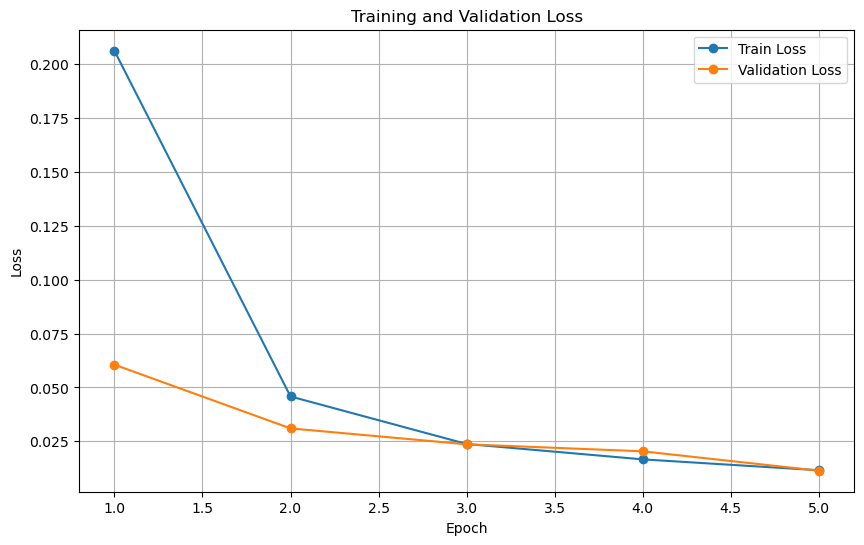

In [45]:
min_len = min(len(history['train_loss']), len(history['val_loss']))

epochs = range(1, min_len + 1)

train_loss = history['train_loss'][:min_len]
val_loss   = history['val_loss'][:min_len]

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_loss, marker='o', label='Train Loss')
plt.plot(epochs, val_loss, marker='o', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


In [46]:
ANGLES = list(range(0, 360, 30))
def rotation_evaluation(model, dataset, device):
    model.eval()

    consistency_scores = []
    confidence_vars = []
    feature_distances = []

    with torch.no_grad():

        for img, label in dataset:

            img = img.unsqueeze(0).to(device)

            preds = []
            confidences = []
            features = []

            for angle in ANGLES:

                rotated = TF.rotate(img.squeeze(0), angle)
                rotated = rotated.unsqueeze(0).to(device)

                logits, feat = forward_with_features(model, rotated)

                prob = torch.softmax(logits, dim=1)

                conf, pred = torch.max(prob, 1)

                preds.append(pred.item())
                confidences.append(conf.item())
                features.append(feat.cpu())

            # consistency
            majority = max(set(preds), key=preds.count)
            consistency = preds.count(majority) / len(preds)
            consistency_scores.append(consistency)

            # confidence variance
            confidence_vars.append(np.var(confidences))

            # feature distance
            base_feat = features[0]
            dists = [torch.norm(base_feat - f).item() for f in features[1:]]
            feature_distances.append(np.mean(dists))

    return consistency_scores, confidence_vars, feature_distances


In [47]:
consistency, conf_var, feat_dist = rotation_evaluation(model, test_data, device)

print("Mean Consistency:", np.mean(consistency))
print("Mean Confidence Variance:", np.mean(conf_var))
print("Mean Feature Distance:", np.mean(feat_dist))


NameError: name 'forward_with_features' is not defined

In [48]:
def rotation_accuracy_curve(model, loader, device):

    acc_per_angle = []

    for angle in ANGLES:

        correct = 0
        total = 0

        for imgs, labels in loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            rotated = torch.stack([
                TF.rotate(img, angle) for img in imgs
            ]).to(device)

            outputs = model(rotated)
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

        acc_per_angle.append(correct / total)

    return acc_per_angle


In [49]:
acc_curve = rotation_accuracy_curve(model, test_loader, device)


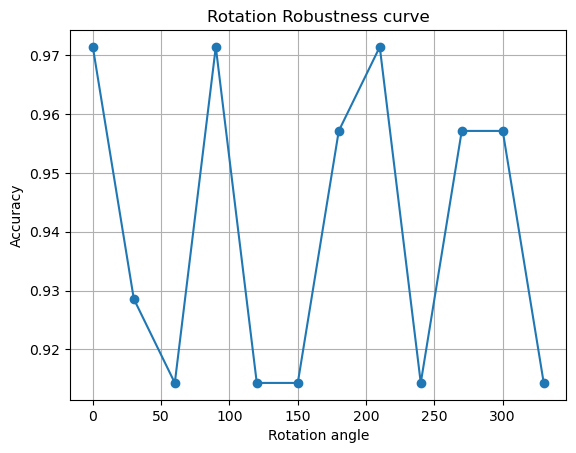

In [50]:
plt.plot(ANGLES, acc_curve, marker='o')
plt.xlabel("Rotation angle")
plt.ylabel("Accuracy")
plt.title("Rotation Robustness curve")

plt.grid(True)
plt.show()


In [52]:
TTA_ANGLES = [0, 45, 90, 135, 180, 225, 270, 315]
ROT_EVAL_ANGLES = list(range(0, 360, 10))


In [53]:
#testing phase
model.eval()
test_running_loss = 0.0
test_correct = 0
test_total = 0

all_test_preds = []
all_test_labels = []
test_bar = tqdm(test_loader, desc='Testing', leave=False)
with torch.no_grad():
    for inputs, labels in test_bar:
        inputs, labels = inputs.to(device), labels.to(device)
        batch_size = inputs.size(0)

        outputs = model(inputs.float())
        loss = criterion(outputs, labels)

        test_running_loss += loss.item() * batch_size
        _, predicted = torch.max(outputs, 1)
        test_total += batch_size
        test_correct += (predicted == labels).sum().item()

        all_test_preds.extend(predicted.cpu().numpy())
        all_test_labels.extend(labels.cpu().numpy())

        test_bar.set_postfix(tloss=loss.item(), tacc=test_correct/test_total if test_total > 0 else 1)
ep_test_loss = test_running_loss / (test_total if test_total > 0 else 1)
ep_test_accuracy = test_correct / (test_total if test_total > 0 else 1)

print(f"Test Loss: {ep_test_loss:.4f} | Test Accuracy: {ep_test_accuracy:.4f}")

# Classification report
print("Classification Report:")
print(classification_report(all_test_labels, all_test_preds, target_names=le.classes_))     
# Confusion matrix
cm = confusion_matrix(all_test_labels, all_test_preds)
print("Confusion Matrix:")
print(cm)

Test Loss: 0.1113 | Test Accuracy: 0.9714
Classification Report:
                    precision    recall  f1-score   support

Class0_Graminicola       1.00      1.00      1.00        35
  Class1_Incognita       0.88      1.00      0.93        14
   Class2_Javanica       1.00      0.90      0.95        21

          accuracy                           0.97        70
         macro avg       0.96      0.97      0.96        70
      weighted avg       0.97      0.97      0.97        70

Confusion Matrix:
[[35  0  0]
 [ 0 14  0]
 [ 0  2 19]]


In [ ]:
# #individual image prediction with visualization

# def predict_image(image_path, model, transform, device):
#     model.eval()
#     image = Image.open(image_path).convert('RGB')
#     image = transform(image).unsqueeze(0)  # Add batch dimension
#     image = image.to(device)

#     with torch.no_grad():
#         outputs = model(image.float())
#         _, predicted = torch.max(outputs, 1)
    
#     return predicted.item()

# # Example usage
# sample_image_path = test_df.iloc[40]['path']

# # Ensure the sample image exists
# if not os.path.exists(sample_image_path):
#     raise FileNotFoundError(f"Sample image not found at {sample_image_path}")   

# # Predict the label for the sample image
# predicted_label_idx = predict_image(sample_image_path, model, val_test_transform, device)
# predicted_label = le.inverse_transform([predicted_label_idx])[0]
# print(f'Predicted label for the sample image: {predicted_label}')   

# # # Visualize the sample image
# # image = Image.open(sample_image_path).convert('RGB')
# # plt.imshow(image)
# # plt.title(f'Predicted Label: {predicted_label}')
# # plt.axis('off')
# # plt.show()

# #comparision with original image
# original_image = Image.open(sample_image_path).convert('RGB')
# original_image_idx
# plt.figure(figsize=(10, 5))
# plt.subplot(1, 2, 1)
# plt.imshow(original_image)
# plt.title('Original Image')
# plt.axis('off')
# plt.subplot(1, 2, 2)
# plt.imshow(image)
# plt.title(f'Predicted Label: {predicted_label}')
# plt.axis('off')
# plt.show()

In [54]:

def predict_and_compare(image_path, true_label, model, transform, device, le):
    model.eval()

    # Load original image
    original_image = Image.open(image_path).convert('RGB')

    # Transform for model input
    image_tensor = transform(original_image).unsqueeze(0).to(device)

    # Prediction
    with torch.no_grad():
        outputs = model(image_tensor.float())
        _, predicted_idx = torch.max(outputs, 1)

    predicted_label = le.inverse_transform([predicted_idx.item()])[0]

    # Plot comparison
    plt.figure(figsize=(10, 4))

    # Original image with true label
    plt.subplot(1, 2, 1)
    plt.imshow(original_image)
    plt.title(f"Original Image\nTrue Label: {true_label}")
    plt.axis("off")

    # Predicted image (same image, different label)
    plt.subplot(1, 2, 2)
    plt.imshow(original_image)
    plt.title(f"Predicted Image\nPredicted Label: {predicted_label}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    return predicted_label


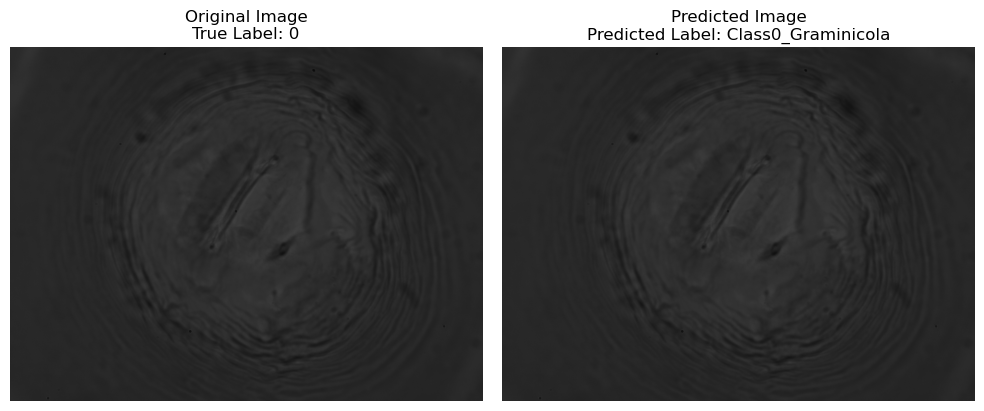

original label :  0
Predicted Label :  Class0_Graminicola


In [55]:
# Pick a sample from test dataframe
idx = 19
sample_image_path = test_df.iloc[idx]['path']
true_label = test_df.iloc[idx]['label']

# Ensure image exists
if not os.path.exists(sample_image_path):
    raise FileNotFoundError(f"Image not found at {sample_image_path}")

# Run prediction + comparison
predicted_label = predict_and_compare(
    image_path=sample_image_path,
    true_label=true_label,
    model=model,
    transform=val_test_transform,
    device=device,
    le=le
)

print("original label : ", true_label)
print("Predicted Label : ", predicted_label)


In [56]:
idx =40
image_path = test_df.iloc[idx]['path']
Original_label = test_df.iloc[idx]['label']

print(f"Image Path: {image_path}")
print(f"Original Label: {Original_label}")


Image Path: /home/dbtproject/barsha/Image/test_set/Class2_Javanica/Meloidogyne javanica_15.tiff
Original Label: 2


In [57]:
def rotate_image(img, angle):
    return TF.rotate(img, angle)


In [58]:
def visualize_rotation_predictions(model, image, label, class_names, device):

    model.eval()

    original_image = Image.open(image_path).convert('RGB')

    angles = [0, 45, 90, 135, 180, 225, 270, 315]

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    with torch.no_grad():

        for ax, angle in zip(axes, angles):

            img_rot = rotate_image(original_image, angle)

            input_tensor = img_rot.unsqueeze(0).to(device)

            output = model(input_tensor.float())
            prob = torch.softmax(output, dim=1)

            conf, pred = torch.max(prob, 1)

            pred_class = class_names[pred.item()]
            conf = conf.item()

            # convert CHW → HWC for plotting
            mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1).to(img_rot.device)
            std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1).to(img_rot.device)

            img_show = img_rot * std + mean        # denormalize
            img_show = img_show.clamp(0, 1)        # keep valid range
            img_show = img_show.permute(1, 2, 0).cpu().numpy()

            ax.imshow(img_show)

            ax.set_title(
                f"{angle}°\nPred: {pred_class}\nConf: {conf:.2f}",
                fontsize=10
            )
            ax.axis("off")

    plt.suptitle(f"True Label: {class_names[label]}", fontsize=14)
    plt.tight_layout()
    plt.show()


In [59]:
data_iter = iter(test_loader)
images, labels = next(data_iter)

image = images[0].to(device)
label = labels[0].item()


AttributeError: 'Image' object has no attribute 'unsqueeze'

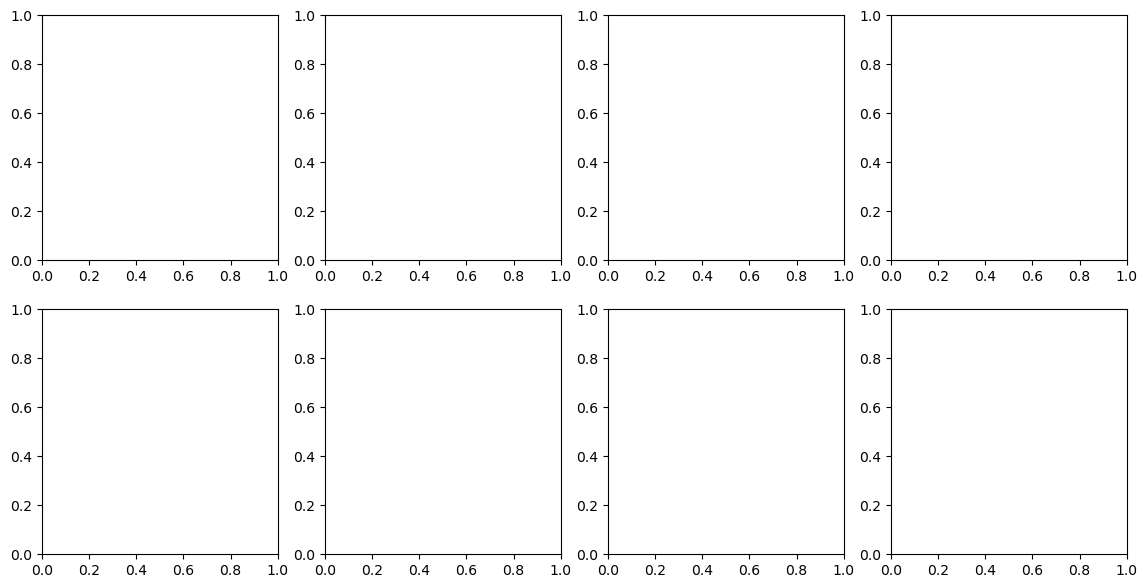

In [60]:
visualize_rotation_predictions(
    model,
    image,
    label,
    le.classes_,   # your class names
    device
)


In [61]:
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
import torch
from PIL import Image

def predict_rotations(image_path, true_label, model, transform, device, le):

    model.eval()

    # Load original image (no normalization here)
    original_image = Image.open(image_path).convert('RGB')

    angles = [0, 45, 90, 135, 180, 225, 270, 315]

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    axes = axes.flatten()

    with torch.no_grad():

        for ax, angle in zip(axes, angles):

            # Rotate ORIGINAL image
            rotated_pil = TF.rotate(original_image, angle)

            # Transform for model
            input_tensor = transform(rotated_pil).unsqueeze(0).to(device)

            outputs = model(input_tensor.float())
            probs = torch.softmax(outputs, dim=1)

            conf, pred = torch.max(probs, 1)

            pred_label = le.inverse_transform([pred.item()])[0]
            conf = conf.item()

            # Show ORIGINAL rotated image 
            ax.imshow(rotated_pil)

            color = "green" if pred_label == true_label else "red"

            ax.set_title(
                f"{angle}°\nPred: {pred_label}\nConf: {conf:.2f}",
                color=color,
                fontsize=10
            )

            ax.axis("off")

    plt.suptitle(f"True Label: {true_label}", fontsize=14)
    plt.tight_layout()
    plt.show()


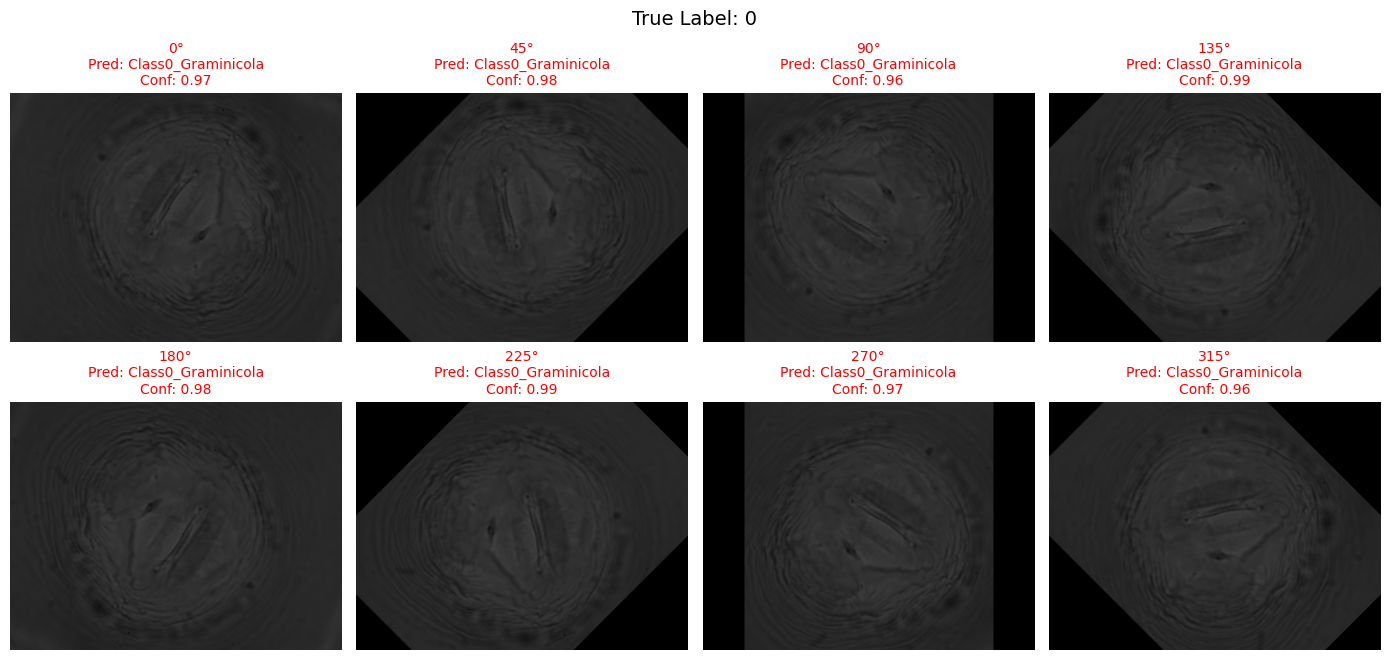

In [62]:
idx = 19
sample_image_path = test_df.iloc[idx]['path']
true_label = test_df.iloc[idx]['label']

predict_rotations(
    image_path=sample_image_path,
    true_label=true_label,
    model=model,
    transform=val_test_transform,
    device=device,
    le=le
)
